In [1]:
from pathlib import Path
import random
import time
import re
import os
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
NUM_CLASSES = 6
PROSTATE_LABEL = 5
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 1e-3  # Match the baseline experiment.
TARGET_SIZE = (256, 144)
TIME_LIMIT_SECONDS = 60 * 60  # Soft limit checked after complete epochs.
RESUME = False  # Set True to continue this experiment's latest checkpoint.

project_dir = Path.cwd()
data_dir = project_dir / "data" / "keras_slices_data"
checkpoint_dir = project_dir / "checkpoints" / "isensse"
checkpoint_dir.mkdir(parents=True, exist_ok=True)
best_path = checkpoint_dir / "isensse_best.pt"
latest_path = checkpoint_dir / "isensse_latest.pt"
history_path = checkpoint_dir / "isensse_history.csv"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LABEL_NAMES = {0: "Outside body", 1: "Remaining tissue", 2: "Bone",
               3: "Bladder", 4: "Rectum", 5: "Prostate"}
# Label names reflect your consultation; preserve their provenance in the README.

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
print("Device:", device)
print("Data:", data_dir)
print("Checkpoints:", checkpoint_dir)
# TODO: pre-activation residual encoder blocks, instance normalisation, leaky ReLU and dropout between convolutions

Device: cuda
Data: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/data/keras_slices_data
Checkpoints: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/isensse


/home/ubuntu/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def find_pairs(root, split):
    images = sorted((root / f"keras_slices_{split}").glob("*.nii.gz"))
    masks = {p.name: p for p in (root / f"keras_slices_seg_{split}").glob("*.nii.gz")}
    if not images:
        raise FileNotFoundError(f"No images found for {split} in {root}")
    expected = {p.name.replace("case_", "seg_", 1) for p in images}
    if expected != set(masks):
        raise ValueError(f"Unmatched image/mask files in {split}")
    return [(p, masks[p.name.replace("case_", "seg_", 1)]) for p in images]

splits = {s: find_pairs(data_dir, s) for s in ("train", "validate", "test")}
patient_sets = {s: {p.name.split("_")[1] for p, _ in pairs}
                for s, pairs in splits.items()}
for a, b in [("train", "validate"), ("train", "test"), ("validate", "test")]:
    assert not patient_sets[a] & patient_sets[b], f"Patient overlap: {a}/{b}"
display(pd.DataFrame([
    {"Split": s, "Pairs": len(pairs), "Patients": len(patient_sets[s])}
    for s, pairs in splits.items()
]))

class HipMRIDataset(Dataset):
    def __init__(self, pairs, target_size=TARGET_SIZE):
        self.pairs = list(pairs)
        self.target_size = target_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        image_nii, mask_nii = nib.load(image_path), nib.load(mask_path)
        
        # Pad size to target size without resizing or stretching
        image = np.squeeze(image_nii.get_fdata(dtype=np.float32))
        mask = np.squeeze(mask_nii.get_fdata())
        
        # Check for invalid images
        if image.ndim != 2 or image.shape != mask.shape:
            raise ValueError(f"Invalid image/mask dimensions: {image_path}")
        if not np.allclose(image_nii.affine, mask_nii.affine):
            raise ValueError(f"Affine mismatch: {image_path}")
        if not np.isfinite(image).all() or not np.isfinite(mask).all():
            raise ValueError(f"Non-finite data: {image_path}")
        if not np.all(mask == np.rint(mask)) or mask.min() < 0 or mask.max() >= NUM_CLASSES:
            raise ValueError(f"Unexpected mask labels: {mask_path}")

        # Normalise
        image = (image - image.mean()) / (image.std() + 1e-8)
        # Greyscale dimension
        image = torch.from_numpy(image.astype(np.float32)).unsqueeze(0)
        # Classes are integers
        mask = torch.from_numpy(mask.astype(np.int64))
        # Add padding based on image size - does not shrink images
        dh, dw = self.target_size[0] - mask.shape[0], self.target_size[1] - mask.shape[1]
        if dh < 0 or dw < 0:
            raise ValueError(f"Slice exceeds target size: {image_path}")
        padding = (dw // 2, dw - dw // 2, dh // 2, dh - dh // 2)
        # Adds the border
        image = nn.functional.pad(image, padding, value=0)
        mask = nn.functional.pad(mask, padding, value=-100)
        return image, mask

train_loader = DataLoader(HipMRIDataset(splits["train"]), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=0, pin_memory=device.type == "cuda")
val_loader = DataLoader(HipMRIDataset(splits["validate"]), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0, pin_memory=device.type == "cuda")
print("Batches (train/validation):", len(train_loader), len(val_loader))


,Split,Pairs,Patients
0,train,11460,31
1,validate,660,4
2,test,540,3


Batches (train/validation): 717 42


In [3]:
class ResidualContextBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(negative_slope=0.01),
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.Dropout2d(dropout) if dropout else nn.Identity(),
            nn.InstanceNorm2d(out_channels, affine=True),
            nn.LeakyReLU(negative_slope=0.01),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
        )
        self.shortcut = (nn.Identity() if in_channels == out_channels
                         else nn.Conv2d(in_channels, out_channels, 1))

    def forward(self, x):
        return self.layers(x) + self.shortcut(x)


def decoder_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1), nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1), nn.ReLU(),
    )

class IsenseeUNet(nn.Module):
    def __init__(self, classes=6, base=16):
        super().__init__()
        # Prepare for the successive layers with increasing / doubling of image
        # resolution
        widths = [base * 2**i for i in range(5)]
        # Prepare the encoder layer list
        self.encoders = nn.ModuleList()
        in_channels = 1
        # Add the successive ResidualContextBlock with increasing image resolution to the encoder
        # layers
        for i, width in enumerate(widths):
            self.encoders.append(ResidualContextBlock(
                in_channels, width, dropout=0.3 if i >= 3 else 0))
            in_channels = width
        self.pool = nn.MaxPool2d(2)
        self.upsamples = nn.ModuleList()
        # Prepare the decoder layer list
        self.decoders = nn.ModuleList()
        # Add the successive ResidualContextBlock with increasing image resolution to the encoder
        # layers
        for i in range(4, 0, -1):
            self.upsamples.append(nn.ConvTranspose2d(
                widths[i], widths[i-1], 3, stride=2, padding=1, output_padding=1))
            self.decoders.append(decoder_block(2 * widths[i-1], widths[i-1]))
        self.output = nn.Conv2d(base, classes, 1)
        # Initialise encoder convolutions for leaky ReLU and decoder ones for ReLU.
        for block in self.encoders:
            for layer in block.modules():
                # fills an input tensor with values sampled from normal distribution
                # using the Kaiming (He) initialization method. This technique is 
                # specifically optimized to preserve variance across deep networks using 
                # rectifying activation functions like ReLU or Leaky ReLU.
                # Also, initialise the bias to zero
                if isinstance(layer, nn.Conv2d):
                    nn.init.kaiming_normal_(layer.weight, a=0.01, nonlinearity="leaky_relu")
                    nn.init.zeros_(layer.bias)
        for block in self.decoders:
            for layer in block.modules():
                if isinstance(layer, nn.Conv2d):
                    nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                    nn.init.zeros_(layer.bias)

    def forward(self, x):
        if x.shape[-2] % 16 or x.shape[-1] % 16:
            raise ValueError("Input height and width must be divisible by 16")
        skips = []
        for encoder in self.encoders[:-1]:
            x = encoder(x)
            skips.append(x)
            x = self.pool(x)
        x = self.encoders[-1](x)
        for upsample, decoder, skip in zip(self.upsamples, self.decoders, reversed(skips)):
            x = decoder(torch.cat([upsample(x), skip], dim=1))
        return self.output(x)  # Raw class scores; do not apply softmax before CE.

# Check shape on CPU, then reset seeds before the actual model initialisation.
check_model = IsenseeUNet().eval()
with torch.inference_mode():
    assert check_model(torch.zeros(1, 1, *TARGET_SIZE)).shape == (1, NUM_CLASSES, *TARGET_SIZE)
del check_model
seed_everything(SEED)
model = IsenseeUNet(classes=NUM_CLASSES, base=16).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss(ignore_index=-100)
print("Parameters:", sum(p.numel() for p in model.parameters()))


[W1029 19:06:08.242703971 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1029 19:06:08.415054598 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.


Parameters: 2204008


In [4]:
def run_epoch(model, loader, training=False):
    model.train(training)
    loss_sum, pixel_count = 0.0, 0
    intersection, predicted_count, target_count = 0, 0, 0
    for images, masks in tqdm(loader, leave=False, mininterval=5):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, masks)
            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite loss encountered")
            if training:
                loss.backward()
                optimizer.step()
        # Exclude the padded cells
        valid = masks != -100
        # Get batches total loss by multiplying average loss with pixels. Convert from tensor to number.
        pixels = valid.sum().item()
        loss_sum += loss.item() * pixels
        pixel_count += pixels
        prediction = logits.detach().argmax(dim=1)
        # Criterion for predicted prostate label.
        pred_prostate = (prediction == PROSTATE_LABEL) & valid
        # Criterion for true prostate label
        true_prostate = (masks == PROSTATE_LABEL) & valid
        # Prediction and truth both positive
        intersection += (pred_prostate & true_prostate).sum().item()
        predicted_count += pred_prostate.sum().item()
        target_count += true_prostate.sum().item()
    denominator = predicted_count + target_count
    dice = 2 * intersection / denominator if denominator else float("nan")
    return loss_sum / pixel_count, dice


In [6]:
# Training and resumable checkpoints
history, best_dice, start_epoch = [], -1.0, 1
# Handle resumable checkpoints
if RESUME:
    # Check for the latest model and load necesssary values
    # Starts from last completed epoch if RESUME is True
    saved = torch.load(latest_path, map_location="cpu", weights_only=False)
    model.load_state_dict(saved["model_state_dict"])
    optimizer.load_state_dict(saved["optimizer_state_dict"])
    history, best_dice = saved["history"], saved["best_dice"]
    start_epoch = saved["epoch"] + 1
    random.setstate(saved["python_rng"])
    np.random.set_state(saved["numpy_rng"])
    torch.set_rng_state(saved["torch_rng"])
    # Restore same RNG state
    if device.type == "cuda" and saved["cuda_rng"] is not None:
        torch.cuda.set_rng_state_all(saved["cuda_rng"])
    del saved
elif latest_path.exists() or best_path.exists():
    raise FileExistsError("Existing experiment found. Set RESUME=True or choose another checkpoint_dir.")


def save_atomic(payload, path):
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    os.replace(temporary, path)

training_start = time.perf_counter()
# Reset necessary stats for collection
if device.type == "cuda":
    torch.cuda.synchronize(device)
    torch.cuda.reset_peak_memory_stats(device)

for epoch in range(start_epoch, EPOCHS + 1):
    # Start time for this epoch and train and validate
    epoch_start = time.perf_counter()
    train_loss, train_dice = run_epoch(model, train_loader, training=True)
    val_loss, val_dice = run_epoch(model, val_loader, training=False)
    seconds = time.perf_counter() - epoch_start
    # Append to history
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                        train_prostate_dice=train_dice, val_prostate_dice=val_dice,
                        seconds=seconds))
    # Check if new best achieved
    improved = val_dice > best_dice
    best_dice = max(best_dice, val_dice)
    # Save payload for resuming
    payload = dict(
        epoch=epoch, model_state_dict=model.state_dict(),
        optimizer_state_dict=optimizer.state_dict(),
        val_prostate_dice=val_dice, best_dice=best_dice, history=history,
        num_classes=NUM_CLASSES, prostate_label=PROSTATE_LABEL, base=16,
        target_size=TARGET_SIZE, model_type="isensee_inspired_2d",
        learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, seed=SEED,
        python_rng=random.getstate(), numpy_rng=np.random.get_state(),
        torch_rng=torch.get_rng_state(),
        cuda_rng=torch.cuda.get_rng_state_all() if device.type == "cuda" else None,
    )
    save_atomic(payload, latest_path)
    if improved:
        save_atomic(payload, best_path)
    del payload
    pd.DataFrame(history).to_csv(history_path, index=False)
    elapsed = time.perf_counter() - training_start
    print(f"Epoch {epoch:02d}/{EPOCHS} | loss {train_loss:.4f} / {val_loss:.4f} | "
          f"prostate Dice {train_dice:.4f} / {val_dice:.4f} | {seconds:.1f}s | "
          f"best val {best_dice:.4f} | elapsed {elapsed/60:.1f} min", flush=True)
    # Check if training time restriction hit
    if elapsed >= TIME_LIMIT_SECONDS:
        print("One-hour soft limit reached; completed epoch saved.")
        break

training_profile = {"Device": str(device), "Completed epochs": len(history),
                    "Recorded epoch time (min)": sum(h["seconds"] for h in history) / 60,
                    "This invocation wall time (min)": (time.perf_counter()-training_start)/60}
if device.type == "cuda":
    training_profile.update({
        "GPU": torch.cuda.get_device_name(device),
        "Invocation peak allocated VRAM (GiB)": torch.cuda.max_memory_allocated(device)/1024**3,
        "Invocation peak reserved VRAM (GiB)": torch.cuda.max_memory_reserved(device)/1024**3})
display(pd.Series(training_profile, name="Training profile").to_frame())
pd.Series(training_profile).to_csv(checkpoint_dir / "isensse_training_profile.csv")
print("Best:", best_path)
print("Latest:", latest_path)


Epoch 01/20 | loss 0.0934 / 0.1141 | prostate Dice 0.6521 / 0.7846 | 126.2s | best val 0.7846 | elapsed 2.1 min


Epoch 02/20 | loss 0.0517 / 0.0996 | prostate Dice 0.8540 / 0.8031 | 119.9s | best val 0.8031 | elapsed 4.1 min


Epoch 03/20 | loss 0.0472 / 0.0947 | prostate Dice 0.8711 / 0.7340 | 122.3s | best val 0.8031 | elapsed 6.2 min


Epoch 04/20 | loss 0.0537 / 0.0872 | prostate Dice 0.8621 / 0.7806 | 128.6s | best val 0.8031 | elapsed 8.3 min


Epoch 05/20 | loss 0.0455 / 0.0948 | prostate Dice 0.8809 / 0.8235 | 122.7s | best val 0.8235 | elapsed 10.4 min


Epoch 06/20 | loss 0.0399 / 0.0914 | prostate Dice 0.8987 / 0.8170 | 126.6s | best val 0.8235 | elapsed 12.5 min


... (11 outputs left out)

Epoch 18/20 | loss 0.0274 / 0.0968 | prostate Dice 0.9276 / 0.7748 | 130.5s | best val 0.8376 | elapsed 37.3 min


Epoch 20/20 | loss 0.0253 / 0.1406 | prostate Dice 0.9336 / 0.8267 | 120.3s | best val 0.8376 | elapsed 41.5 min


,Training profile
Device,cuda
Completed epochs,20
Recorded epoch time (min),41.380841
This invocation wall time (min),41.54483
GPU,NVIDIA A100-SXM4-40GB
Invocation peak allocated VRAM (GiB),0.846069
Invocation peak reserved VRAM (GiB),1.001953


Best: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/isensse/isensse_best.pt
Latest: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/isensse/isensse_latest.pt


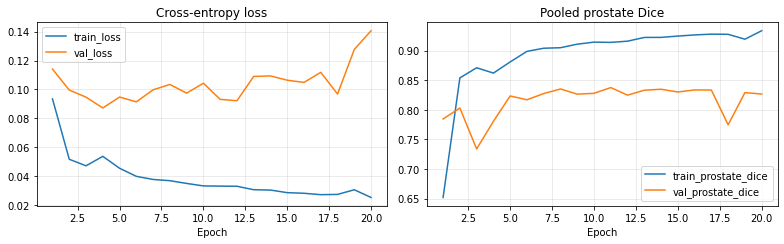

In [7]:
frame = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for column in ["train_loss", "val_loss"]:
    axes[0].plot(frame.epoch, frame[column], label=column)
for column in ["train_prostate_dice", "val_prostate_dice"]:
    axes[1].plot(frame.epoch, frame[column], label=column)
for ax, title in zip(axes, ["Cross-entropy loss", "Pooled prostate Dice"]):
    ax.set(xlabel="Epoch", title=title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# Release training-only tensors before constructing the inference model.
model.to("cpu")
del model, optimizer
if device.type == "cuda":
    torch.cuda.empty_cache()
checkpoint = torch.load(best_path, map_location="cpu", weights_only=False)
preview_model = IsenseeUNet(classes=checkpoint["num_classes"], base=checkpoint["base"])
preview_model.load_state_dict(checkpoint["model_state_dict"])
preview_model = preview_model.to(device).eval()
checkpoint_epoch = checkpoint["epoch"]
checkpoint_dice = checkpoint["val_prostate_dice"]
del checkpoint  # Do not keep checkpoint optimiser tensors around.

indices = np.linspace(0, len(val_loader.dataset)-1,
                      num=min(100, len(val_loader.dataset)), dtype=int)
inputs = [val_loader.dataset[int(i)][0].unsqueeze(0) for i in indices]
def synchronise():
    if device.type == "cuda":
        torch.cuda.synchronize(device)

times_ms = []
with torch.inference_mode():
    warmup = inputs[0].to(device)
    for _ in range(10):
        output = preview_model(warmup).argmax(dim=1)
    del output, warmup
    synchronise()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    for cpu_image in inputs:
        image = cpu_image.to(device)
        synchronise()
        start = time.perf_counter()
        prediction = preview_model(image).argmax(dim=1)
        synchronise()
        times_ms.append((time.perf_counter()-start)*1000)
        del prediction, image
results = {"Model": "isensee_inspired_2d", "Checkpoint epoch": checkpoint_epoch,
           "Validation prostate Dice": checkpoint_dice,
           "Parameters": sum(p.numel() for p in preview_model.parameters()),
           "Inference batch size": 1, "Slices measured": len(times_ms),
           "Mean inference time (ms/slice)": np.mean(times_ms),
           "Median inference time (ms/slice)": np.median(times_ms),
           "95th percentile time (ms/slice)": np.percentile(times_ms, 95)}
if device.type == "cuda":
    results.update({"GPU": torch.cuda.get_device_name(device),
                    "Peak inference allocated VRAM (GiB)": torch.cuda.max_memory_allocated(device)/1024**3,
                    "Peak inference reserved VRAM (GiB)": torch.cuda.max_memory_reserved(device)/1024**3})
profile = pd.Series(results, name="Resource profile").to_frame()
display(profile)
profile.to_csv(checkpoint_dir / "isensse_resource_profile.csv")


,Resource profile
Model,isensee_inspired_2d
Checkpoint epoch,11
Validation prostate Dice,0.837649
Parameters,2204008
Inference batch size,1
Slices measured,100
Mean inference time (ms/slice),3.188301
Median inference time (ms/slice),3.186774
95th percentile time (ms/slice),3.210143
GPU,NVIDIA A100-SXM4-40GB


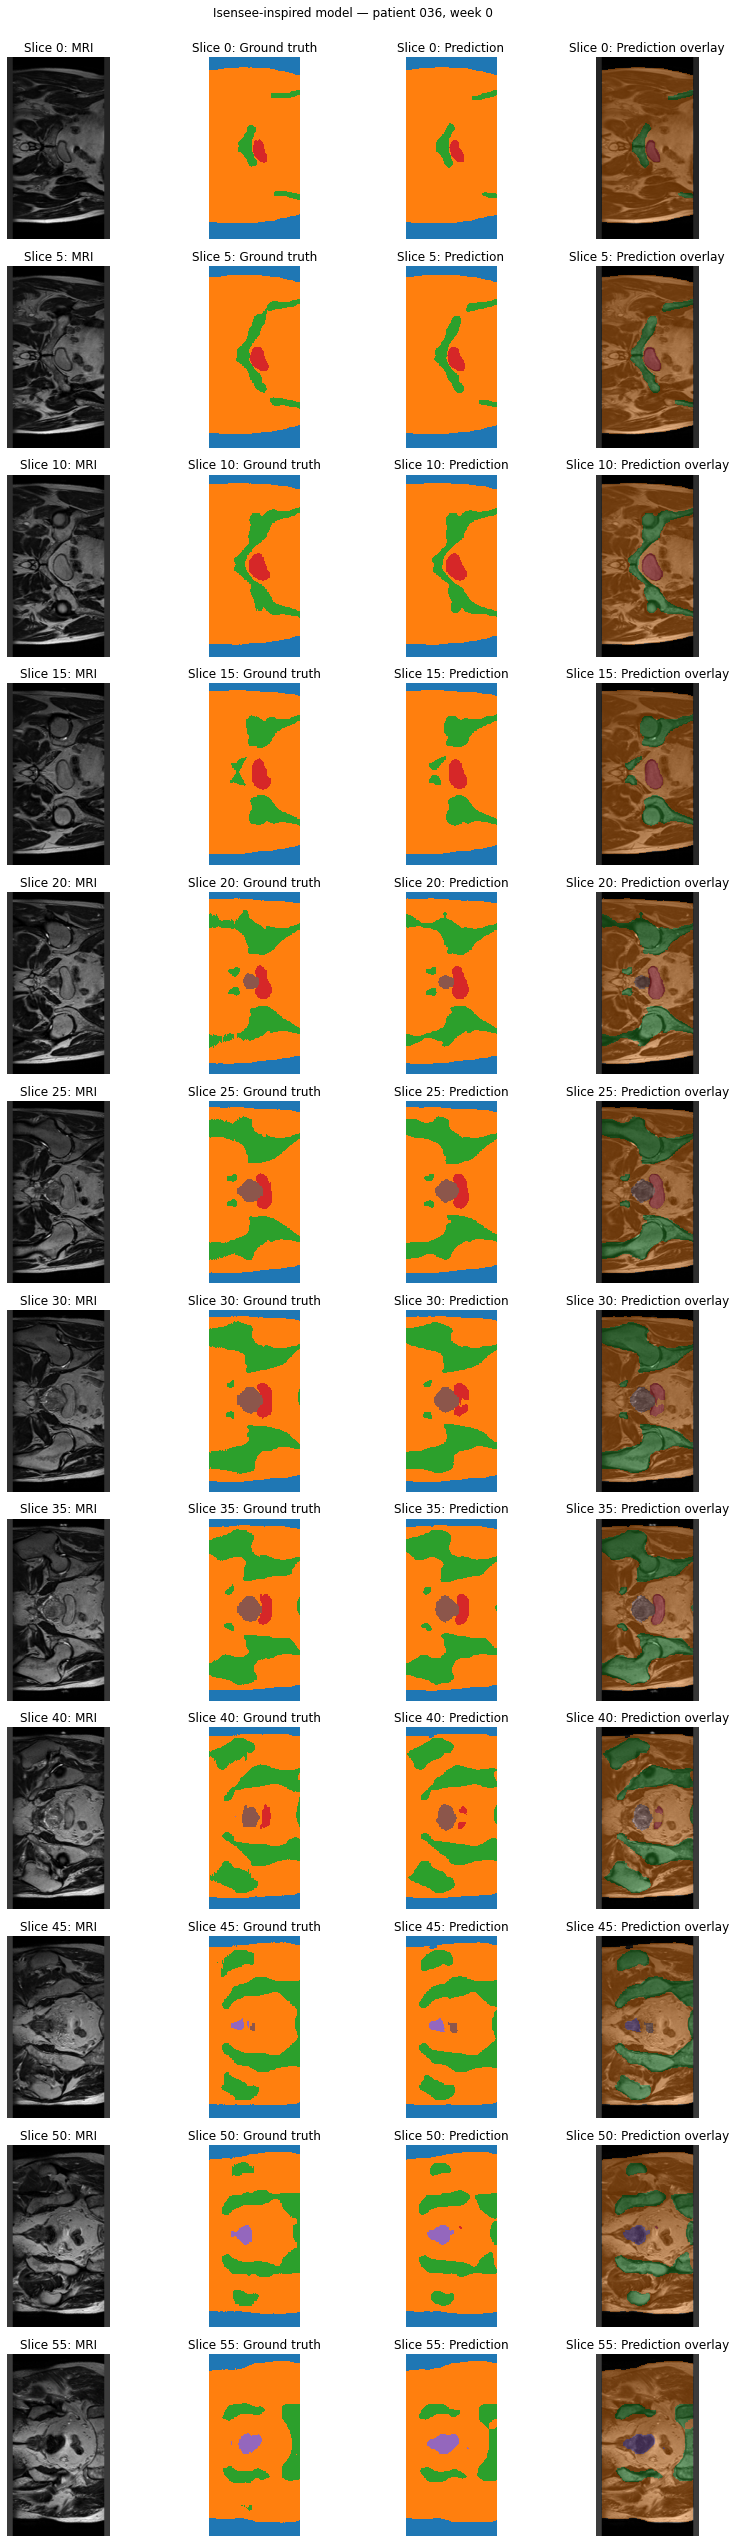

In [9]:
# Pick a slice and week, sorted numerically before selecting every fifth slice
PATIENT_ID = "036"  # Validation patients: 036, 037, 038, 039.
WEEK = 0
case_pairs = [pair for pair in splits["validate"]
              if pair[0].name.startswith(f"case_{PATIENT_ID}_week_{WEEK}_slice_")]
case_pairs.sort(key=lambda pair: int(re.search(r"_slice_(\d+)", pair[0].name).group(1)))
selected = case_pairs[::5]
assert selected, "No matching slices found; check patient ID and week."
preview_dataset = HipMRIDataset(selected)
fig, axes = plt.subplots(len(selected), 4, figsize=(12, 3*len(selected)), squeeze=False)
colours = dict(cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
for row, (image_path, _) in enumerate(selected):
    image, mask = preview_dataset[row]
    with torch.inference_mode():
        prediction = preview_model(image.unsqueeze(0).to(device)).argmax(1)[0].cpu().numpy()
    image, mask = image[0].numpy(), mask.numpy()
    valid = mask != -100
    slice_number = re.search(r"_slice_(\d+)", image_path.name).group(1)
    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 1].imshow(np.ma.masked_where(~valid, mask), **colours)
    axes[row, 2].imshow(np.ma.masked_where(~valid, prediction), **colours)
    axes[row, 3].imshow(image, cmap="gray")
    axes[row, 3].imshow(np.ma.masked_where((prediction == 0) | ~valid, prediction),
                        alpha=0.4, **colours)
    for ax, title in zip(axes[row], ["MRI", "Ground truth", "Prediction", "Prediction overlay"]):
        ax.set_title(f"Slice {slice_number}: {title}")
        ax.axis("off")
fig.suptitle(f"Isensee-inspired model — patient {PATIENT_ID}, week {WEEK}")
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


In [10]:
from scipy.ndimage import binary_erosion, distance_transform_edt

# Calculate symmetric HD95 between the boundaries of two binary masks.
def calculate_hd95(predicted, reference):
    if not predicted.any() and not reference.any():
        return np.nan  # No structure present: boundary distance is undefined.

    if not predicted.any() or not reference.any():
        return np.inf  # A structure was completely missed or falsely predicted.

    predicted_boundary = predicted & ~binary_erosion(
        predicted, border_value=0
    )
    reference_boundary = reference & ~binary_erosion(
        reference, border_value=0
    )

    # Distance from every pixel to the closest boundary pixel.
    distance_to_reference = distance_transform_edt(~reference_boundary)
    distance_to_prediction = distance_transform_edt(~predicted_boundary)

    distances = np.concatenate([
        distance_to_reference[predicted_boundary],
        distance_to_prediction[reference_boundary],
    ])
    return float(np.percentile(distances, 95))


# Accumulate overlap counts across all validation slices.
intersections = np.zeros(NUM_CLASSES, dtype=np.int64)
predicted_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
reference_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
boundary_distances = [[] for _ in range(NUM_CLASSES)]

preview_model.eval()

with torch.inference_mode():
    for images, masks in tqdm(
        val_loader, desc="Validation metrics", mininterval=5
    ):
        predictions = (
            preview_model(images.to(device))
            .argmax(dim=1)
            .cpu()
            .numpy()
        )
        masks = masks.numpy()

        for prediction, reference in zip(predictions, masks):
            valid = reference != -100

            # Remove padding before extracting boundaries.
            rows, columns = np.where(valid)
            region = (
                slice(rows.min(), rows.max() + 1),
                slice(columns.min(), columns.max() + 1),
            )
            prediction = prediction[region]
            reference = reference[region]
            valid = valid[region]

            for label in range(NUM_CLASSES):
                predicted = (prediction == label) & valid
                actual = (reference == label) & valid

                intersections[label] += (predicted & actual).sum()
                predicted_counts[label] += predicted.sum()
                reference_counts[label] += actual.sum()
                boundary_distances[label].append(
                    calculate_hd95(predicted, actual)
                )

results = []

for label in range(NUM_CLASSES):
    intersection = intersections[label]
    denominator = predicted_counts[label] + reference_counts[label]
    union = denominator - intersection

    distances = np.asarray(boundary_distances[label])
    finite_distances = distances[np.isfinite(distances)]

    results.append({
        "Label": label,
        "Structure": LABEL_NAMES[label],
        "Dice": 2 * intersection / denominator if denominator else np.nan,
        "IoU": intersection / union if union else np.nan,
        "Mean HD95, finite slices (pixels)": (
            finite_distances.mean() if finite_distances.size else np.nan
        ),
        "Finite HD95 slices": int(np.isfinite(distances).sum()),
        "One mask empty (HD95 infinite)": int(np.isinf(distances).sum()),
        "Both masks empty (HD95 undefined)": int(np.isnan(distances).sum()),
    })

metrics = pd.DataFrame(results).set_index("Label")
display(metrics.round(4))

print("Prostate results:")
display(metrics.loc[[PROSTATE_LABEL]].round(4))

metrics.to_csv(checkpoint_dir / "isensse_validation_metrics.csv")

Validation metrics: 100%|██████████| 42/42 [00:16<00:00,  2.55it/s]


,Structure,Dice,IoU,"Mean HD95, finite slices (pixels)",Finite HD95 slices,One mask empty (HD95 infinite),Both masks empty (HD95 undefined)
Label,,,,,,,
0,Outside body,0.9949,0.9898,0.4451,660,0,0
1,Remaining tissue,0.9813,0.9633,2.8259,660,0,0
2,Bone,0.9295,0.8684,7.0712,660,0,0
3,Bladder,0.8638,0.7603,4.6199,453,23,184
4,Rectum,0.8682,0.7670,7.0871,248,21,391
5,Prostate,0.8376,0.7206,4.3527,232,38,390


Prostate results:


,Structure,Dice,IoU,"Mean HD95, finite slices (pixels)",Finite HD95 slices,One mask empty (HD95 infinite),Both masks empty (HD95 undefined)
Label,,,,,,,
5,Prostate,0.8376,0.7206,4.3527,232,38,390


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from scipy.ndimage import binary_erosion, distance_transform_edt
from tqdm.auto import tqdm

# Select model

# ISENSEE
MODEL_NAME = "isensee"
MODEL_CLASS = IsenseeUNet
CHECKPOINT = project_dir / "checkpoints" / "isensse" / "isensse_best.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

checkpoint = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=False
)

test_model = MODEL_CLASS(
    classes=checkpoint["num_classes"],
    base=checkpoint["base"],
)
test_model.load_state_dict(checkpoint["model_state_dict"])
test_model = test_model.to(device).eval()

num_classes = checkpoint["num_classes"]
target_size = tuple(checkpoint["target_size"])
prostate_label = checkpoint["prostate_label"]

print("Model:", MODEL_NAME)
print("Best checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation Dice:", checkpoint["val_prostate_dice"])

# Release the checkpoint's optimiser tensors.
del checkpoint

# Load test set

test_dataset = HipMRIDataset(
    splits["test"],
    target_size=target_size,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

label_names = {
    0: "Outside body",
    1: "Remaining tissue",
    2: "Bone",
    3: "Bladder",
    4: "Rectum",
    5: "Prostate",
}

print("Test slices:", len(test_dataset))

# Define H95

def test_hd95(predicted, reference):
    if not predicted.any() and not reference.any():
        return np.nan

    if not predicted.any() or not reference.any():
        return np.inf

    predicted_boundary = predicted & ~binary_erosion(
        predicted, border_value=0
    )
    reference_boundary = reference & ~binary_erosion(
        reference, border_value=0
    )

    distance_to_reference = distance_transform_edt(
        ~reference_boundary
    )
    distance_to_prediction = distance_transform_edt(
        ~predicted_boundary
    )

    distances = np.concatenate([
        distance_to_reference[predicted_boundary],
        distance_to_prediction[reference_boundary],
    ])
    return float(np.percentile(distances, 95))

# Evaluate predictions (DO NOT CHANGE MODEL WEIGHTS)

intersections = np.zeros(num_classes, dtype=np.int64)
predicted_counts = np.zeros(num_classes, dtype=np.int64)
reference_counts = np.zeros(num_classes, dtype=np.int64)
slice_records = []
sample_index = 0

with torch.inference_mode():
    for images, masks in tqdm(
        test_loader, desc=f"Testing {MODEL_NAME}", mininterval=5
    ):
        predictions = (
            test_model(images.to(device))
            .argmax(dim=1)
            .cpu()
            .numpy()
        )
        masks = masks.numpy()

        for prediction, reference in zip(predictions, masks):
            image_path = Path(splits["test"][sample_index][0])
            sample_index += 1

            # Crop away the artificial padding before measuring boundaries.
            valid = reference != -100
            rows, columns = np.where(valid)
            region = (
                slice(rows.min(), rows.max() + 1),
                slice(columns.min(), columns.max() + 1),
            )
            prediction = prediction[region]
            reference = reference[region]
            valid = valid[region]

            for label in range(num_classes):
                predicted = (prediction == label) & valid
                actual = (reference == label) & valid

                intersection = int((predicted & actual).sum())
                predicted_count = int(predicted.sum())
                reference_count = int(actual.sum())

                intersections[label] += intersection
                predicted_counts[label] += predicted_count
                reference_counts[label] += reference_count

                denominator = predicted_count + reference_count
                union = denominator - intersection

                slice_records.append({
                    "model": MODEL_NAME,
                    "file": image_path.name,
                    "patient": image_path.name.split("_")[1],
                    "label": label,
                    "structure": label_names[label],
                    "dice": (
                        2 * intersection / denominator
                        if denominator else np.nan
                    ),
                    "iou": intersection / union if union else np.nan,
                    "hd95_pixels": test_hd95(predicted, actual),
                    "false_negative_pixels": int(
                        (actual & ~predicted).sum()
                    ),
                    "false_positive_pixels": int(
                        (predicted & ~actual).sum()
                    ),
                    "missed_structure": (
                        reference_count > 0 and predicted_count == 0
                    ),
                    "false_structure": (
                        reference_count == 0 and predicted_count > 0
                    ),
                    "both_empty": denominator == 0,
                })

# Evaluate boundaries

slice_metrics = pd.DataFrame(slice_records)
summary = []

for label in range(num_classes):
    subset = slice_metrics[slice_metrics["label"] == label]
    distances = subset["hd95_pixels"].to_numpy()
    finite = distances[np.isfinite(distances)]

    denominator = predicted_counts[label] + reference_counts[label]
    union = denominator - intersections[label]

    summary.append({
        "Label": label,
        "Structure": label_names[label],
        "Dice": (
            2 * intersections[label] / denominator
            if denominator else np.nan
        ),
        "IoU": (
            intersections[label] / union if union else np.nan
        ),
        "Mean finite HD95 (pixels)": (
            finite.mean() if finite.size else np.nan
        ),
        "Finite HD95 slices": int(np.isfinite(distances).sum()),
        "Missed structure slices": int(subset["missed_structure"].sum()),
        "False structure slices": int(subset["false_structure"].sum()),
        "Both empty slices": int(subset["both_empty"].sum()),
    })

test_metrics = pd.DataFrame(summary).set_index("Label")

print(f"\n{MODEL_NAME}: held-out test results")
display(test_metrics.round(4))

print("\nProstate:")
display(test_metrics.loc[[prostate_label]].round(4))

# Save summaries and individual slices for later failure analysis.
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

test_metrics.to_csv(results_dir / f"{MODEL_NAME}_test_metrics.csv")
slice_metrics.to_csv(
    results_dir / f"{MODEL_NAME}_test_slice_metrics.csv",
    index=False,
)

print("Saved results to:", results_dir)

Model: isensee
Best checkpoint epoch: 11
Checkpoint validation Dice: 0.8376485446925771
Test slices: 540


Testing isensee: 100%|██████████| 34/34 [00:17<00:00,  1.92it/s]


isensee: held-out test results


,Structure,Dice,IoU,Mean finite HD95 (pixels),Finite HD95 slices,Missed structure slices,False structure slices,Both empty slices
Label,,,,,,,,
0,Outside body,0.9967,0.9934,0.1785,540,0,0,0
1,Remaining tissue,0.9841,0.9687,2.2705,540,0,0,0
2,Bone,0.9332,0.8748,5.1638,540,0,0,0
3,Bladder,0.9648,0.9321,1.6988,395,6,8,131
4,Rectum,0.8480,0.7361,6.2695,214,6,4,316
5,Prostate,0.8549,0.7466,3.3788,181,14,4,341



Prostate:


,Structure,Dice,IoU,Mean finite HD95 (pixels),Finite HD95 slices,Missed structure slices,False structure slices,Both empty slices
Label,,,,,,,,
5,Prostate,0.8549,0.7466,3.3788,181,14,4,341


Saved results to: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/results


In [12]:
import pandas as pd

results_dir = project_dir / "results"

# Read filenames as strings to preserve patient IDs such as "040".
baseline = pd.read_csv(
    results_dir / "baseline_test_slice_metrics.csv",
    dtype={"patient": str},
)
isensee = pd.read_csv(
    results_dir / "isensee_test_slice_metrics.csv",
    dtype={"patient": str},
)

# Focus on prostate, label 5.
baseline = baseline[baseline["label"] == 5].copy()
isensee = isensee[isensee["label"] == 5].copy()

comparison = baseline.merge(
    isensee,
    on=["file", "patient", "label"],
    suffixes=("_baseline", "_isensee"),
    validate="one_to_one",
)

comparison["dice_change"] = (
    comparison["dice_isensee"] - comparison["dice_baseline"]
)

columns = [
    "file",
    "dice_baseline",
    "dice_isensee",
    "false_negative_pixels_baseline",
    "false_negative_pixels_isensee",
    "false_positive_pixels_baseline",
    "false_positive_pixels_isensee",
]

print("Largest amounts of missed prostate tissue in the baseline:")
display(
    comparison.sort_values(
        "false_negative_pixels_baseline", ascending=False
    )[columns].head(5)
)

print("Largest amounts of incorrectly included tissue in the baseline:")
display(
    comparison.sort_values(
        "false_positive_pixels_baseline", ascending=False
    )[columns].head(5)
)

print("Largest Dice improvements with Isensee:")
display(
    comparison.sort_values("dice_change", ascending=False)[columns].head(5)
)

print("Largest Dice reductions with Isensee:")
display(
    comparison.sort_values("dice_change")[columns].head(5)
)

Largest amounts of missed prostate tissue in the baseline:


,file,dice_baseline,dice_isensee,false_negative_pixels_baseline,false_negative_pixels_isensee,false_positive_pixels_baseline,false_positive_pixels_isensee
489,case_042_week_0_slice_17.nii.gz,0.740373,0.837416,208,130,1,16
488,case_042_week_0_slice_16.nii.gz,0.709040,0.848411,206,110,0,14
512,case_042_week_0_slice_38.nii.gz,0.062016,0.066351,190,191,52,6
484,case_042_week_0_slice_12.nii.gz,0.000000,0.292237,182,150,0,5
485,case_042_week_0_slice_13.nii.gz,0.334572,0.484848,179,144,0,26


Largest amounts of incorrectly included tissue in the baseline:


,file,dice_baseline,dice_isensee,false_negative_pixels_baseline,false_negative_pixels_isensee,false_positive_pixels_baseline,false_positive_pixels_isensee
453,case_041_week_0_slice_39.nii.gz,0.476427,0.531507,1,0,210,171
455,case_041_week_0_slice_40.nii.gz,0.256228,0.308370,0,1,209,156
452,case_041_week_0_slice_38.nii.gz,0.639719,0.751620,6,14,199,101
201,case_040_week_3_slice_28.nii.gz,0.791418,0.775656,0,7,175,181
266,case_040_week_4_slice_32.nii.gz,0.490028,0.494845,6,20,173,127


Largest Dice improvements with Isensee:


,file,dice_baseline,dice_isensee,false_negative_pixels_baseline,false_negative_pixels_isensee,false_positive_pixels_baseline,false_positive_pixels_isensee
316,case_040_week_5_slice_23.nii.gz,0.000000,0.726190,104,43,0,3
131,case_040_week_2_slice_19.nii.gz,0.086957,0.784615,63,15,0,13
370,case_040_week_7_slice_18.nii.gz,0.000000,0.674157,48,18,0,11
389,case_040_week_7_slice_35.nii.gz,0.125000,0.605714,55,6,1,63
93,case_040_week_1_slice_39.nii.gz,0.000000,0.423077,81,59,0,1


Largest Dice reductions with Isensee:


,file,dice_baseline,dice_isensee,false_negative_pixels_baseline,false_negative_pixels_isensee,false_positive_pixels_baseline,false_positive_pixels_isensee
249,case_040_week_4_slice_17.nii.gz,0.670520,0.000000,57,115,0,0
188,case_040_week_3_slice_16.nii.gz,0.609137,0.000000,77,137,0,0
151,case_040_week_2_slice_37.nii.gz,0.642424,0.063830,38,88,21,0
31,case_040_week_0_slice_37.nii.gz,0.558559,0.329588,80,160,116,19
335,case_040_week_5_slice_40.nii.gz,0.748603,0.540541,41,68,4,0


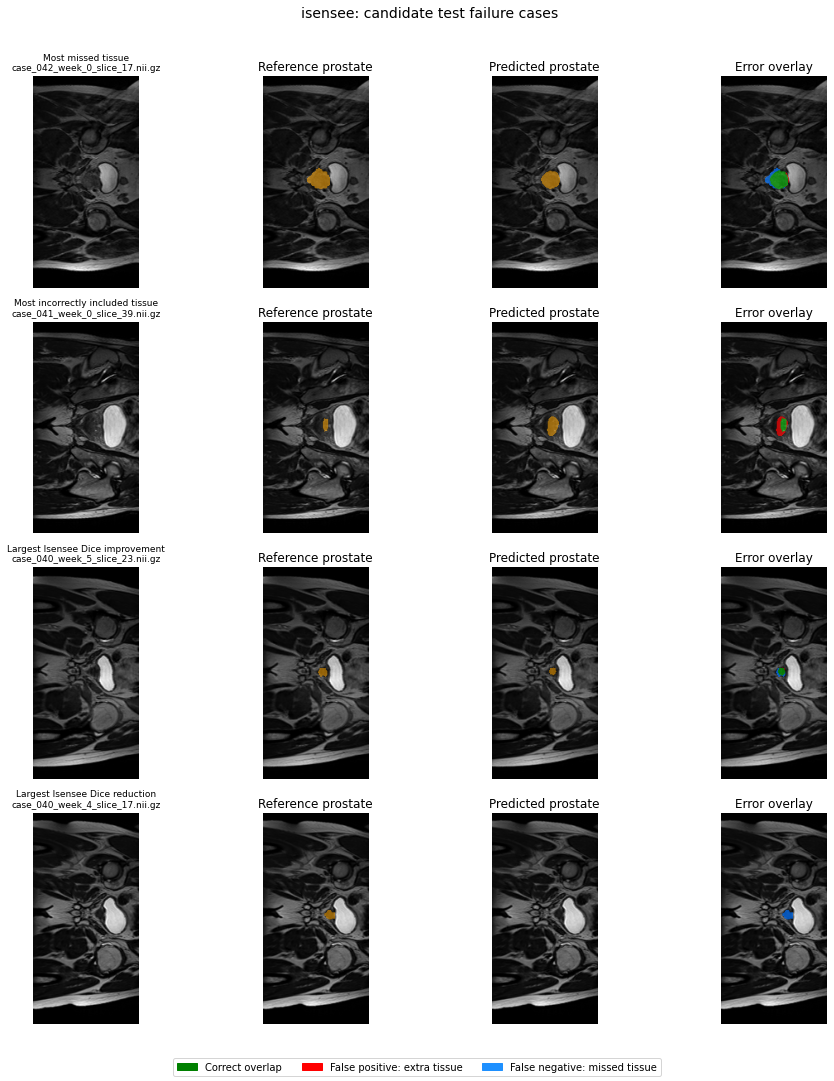

Saved: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/results/figures/isensee_failure_candidates.png


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Read the results used to select common examples.
baseline = pd.read_csv(
    project_dir / "results" / "baseline_test_slice_metrics.csv"
)
isensee = pd.read_csv(
    project_dir / "results" / "isensee_test_slice_metrics.csv"
)

comparison = baseline[baseline["label"] == 5].merge(
    isensee[isensee["label"] == 5],
    on=["file", "patient", "label"],
    suffixes=("_baseline", "_isensee"),
    validate="one_to_one",
)
comparison["dice_change"] = (
    comparison["dice_isensee"] - comparison["dice_baseline"]
)

# Select a different candidate for each category.
# These rankings suggest examples; visual inspection determines the failure.
rankings = [
    (
        "Most missed tissue",
        comparison.sort_values(
            "false_negative_pixels_baseline", ascending=False
        ),
    ),
    (
        "Most incorrectly included tissue",
        comparison.sort_values(
            "false_positive_pixels_baseline", ascending=False
        ),
    ),
    (
        "Largest Isensee Dice improvement",
        comparison.dropna(subset=["dice_change"]).sort_values(
            "dice_change", ascending=False
        ),
    ),
    (
        "Largest Isensee Dice reduction",
        comparison.dropna(subset=["dice_change"]).sort_values(
            "dice_change"
        ),
    ),
]

selected, used = [], set()
for category, ranked in rankings:
    for filename in ranked["file"]:
        if filename not in used:
            selected.append((category, filename))
            used.add(filename)
            break

# Match the selected filenames to actual TEST images and masks.
test_pairs_by_name = {
    pair[0].name: pair for pair in splits["test"]
}
selected_pairs = [
    test_pairs_by_name[filename] for _, filename in selected
]

# Use the target size loaded with this model's checkpoint.
examples = HipMRIDataset(selected_pairs, target_size=target_size)

fig, axes = plt.subplots(
    len(selected), 4,
    figsize=(14, 3.8 * len(selected)),
    squeeze=False,
)

test_model.eval()

for row, (category, filename) in enumerate(selected):
    image, mask = examples[row]

    with torch.inference_mode():
        prediction = (
            test_model(image.unsqueeze(0).to(device))
            .argmax(dim=1)[0]
            .cpu().numpy()
        )

    image = image[0].numpy()
    mask = mask.numpy()

    # Crop away padding so it does not appear in the figures.
    valid = mask != -100
    rows, columns = np.where(valid)
    region = (
        slice(rows.min(), rows.max() + 1),
        slice(columns.min(), columns.max() + 1),
    )
    image = image[region]
    mask = mask[region]
    prediction = prediction[region]

    actual = mask == 5
    predicted = prediction == 5

    true_positive = actual & predicted
    false_positive = predicted & ~actual
    false_negative = actual & ~predicted

    # Show prostate only, keeping the MRI visible underneath.
    axes[row, 0].imshow(image, cmap="gray")

    for column, binary_mask in [(1, actual), (2, predicted)]:
        axes[row, column].imshow(image, cmap="gray")
        overlay = np.zeros((*binary_mask.shape, 4))
        overlay[binary_mask] = [1, 0.65, 0, 0.55]
        axes[row, column].imshow(overlay)

    # Green: correct overlap; red: extra tissue; blue: missed tissue.
    error_overlay = np.zeros((*actual.shape, 4))
    error_overlay[true_positive] = [0, 1, 0, 0.45]
    error_overlay[false_positive] = [1, 0, 0, 0.7]
    error_overlay[false_negative] = [0, 0.45, 1, 0.7]

    axes[row, 3].imshow(image, cmap="gray")
    axes[row, 3].imshow(error_overlay)

    for ax, title in zip(
        axes[row],
        ["MRI", "Reference prostate", "Predicted prostate", "Error overlay"],
    ):
        ax.set_title(title)
        ax.axis("off")

    # Identify the exact case and the reason it was selected.
    axes[row, 0].set_title(
        f"{category}\n{filename}", fontsize=9
    )

legend = [
    Patch(color="green", label="Correct overlap"),
    Patch(color="red", label="False positive: extra tissue"),
    Patch(color="dodgerblue", label="False negative: missed tissue"),
]
fig.legend(handles=legend, loc="lower center", ncol=3)
fig.suptitle(f"{MODEL_NAME}: candidate test failure cases", fontsize=14)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])

output_dir = project_dir / "results" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{MODEL_NAME}_failure_candidates.png"
fig.savefig(output_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", output_path)

In [14]:
# Display per-slice prostate metrics for the visualised cases.
results_dir = project_dir / "results"

model_files = {
    "Baseline": "baseline_test_slice_metrics.csv",
    "Residual": "residual_test_slice_metrics.csv",
    "Isensee-inspired": "isensee_test_slice_metrics.csv",
}

case_results = []

for model_name, filename in model_files.items():
    csv_path = results_dir / filename

    if not csv_path.exists():
        print(f"Skipping {model_name}: {filename} not found.")
        continue

    frame = pd.read_csv(csv_path)
    prostate = frame[frame["label"] == 5]

    for category, case_filename in selected:
        matching = prostate[prostate["file"] == case_filename]

        if matching.empty:
            print(f"No result for {model_name}: {case_filename}")
            continue

        result = matching.iloc[0]

        case_results.append({
            "Selection": category,
            "Slice": case_filename,
            "Model": model_name,
            "Dice": result["dice"],
            "IoU": result["iou"],
            "HD95 (pixels)": result["hd95_pixels"],
            "Missed pixels": result["false_negative_pixels"],
            "Extra pixels": result["false_positive_pixels"],
        })

case_metrics = pd.DataFrame(case_results)

for category, case_filename in selected:
    print(f"\n{category}: {case_filename}")

    display(
        case_metrics[case_metrics["Slice"] == case_filename]
        .set_index("Model")[
            ["Dice", "IoU", "HD95 (pixels)", "Missed pixels", "Extra pixels"]
        ]
        .round(4)
    )

case_metrics.to_csv(
    results_dir / "selected_failure_case_metrics.csv",
    index=False,
)


Most missed tissue: case_042_week_0_slice_17.nii.gz


,Dice,IoU,HD95 (pixels),Missed pixels,Extra pixels
Model,,,,,
Baseline,0.7404,0.5878,6.2278,208,1
Residual,0.6649,0.4980,8.7000,254,0
Isensee-inspired,0.8374,0.7203,5.0149,130,16



Most incorrectly included tissue: case_041_week_0_slice_39.nii.gz


,Dice,IoU,HD95 (pixels),Missed pixels,Extra pixels
Model,,,,,
Baseline,0.4764,0.3127,7.2111,1,210
Residual,0.4409,0.2828,8.5440,0,246
Isensee-inspired,0.5315,0.3619,6.7082,0,171



Largest Isensee Dice improvement: case_040_week_5_slice_23.nii.gz


,Dice,IoU,HD95 (pixels),Missed pixels,Extra pixels
Model,,,,,
Baseline,0.0000,0.0000,inf,104,0
Residual,0.0917,0.0481,5.4123,99,0
Isensee-inspired,0.7262,0.5701,3.0000,43,3



Largest Isensee Dice reduction: case_040_week_4_slice_17.nii.gz


,Dice,IoU,HD95 (pixels),Missed pixels,Extra pixels
Model,,,,,
Baseline,0.6705,0.5043,3.1623,57,0
Residual,0.5157,0.3475,4.0185,74,3
Isensee-inspired,0.0000,0.0000,inf,115,0
